### Analysing branches of the trajectory

<div class="alert alert-block alert-info">
<b>PILOT</b>

A trajectory can have several parts or branches, e.g. one branch towards a disease sub-type and another one towards a different sub-type, or a healthy part and a disease part. The cell types that change can be different in each branch. In this tutorial we show how to split the trajectory by choosing nodes of the principal graph, and how to run the cell type importance (and the rest of the analysis) for each branch separately.

We use the Myocardial Infarction data. You can download the Anndata (h5ad) file from [here](https://costalab.ukaachen.de/open_data/PILOT/myocardial_infarction.h5ad), and place it in the _Datasets_ folder. The first steps are the same as in the [Myocardial Infarction tutorial](https://pilot.readthedocs.io/en/latest/Myocardial_infarction.html).
</div>

In [ ]:
import pilotpy as pl
import scanpy as sc
import matplotlib.pyplot as plt

##### Reading Anndata

In [ ]:
adata = sc.read_h5ad('Datasets/myocardial_infarction.h5ad')

##### Wasserstein distance and trajectory:
<div class="alert alert-block alert-info">
We compute the Wasserstein distances between the samples and the trajectory, as in the Myocardial Infarction tutorial.
</div>

In [ ]:
pl.tl.wasserstein_distance(
    adata,
    emb_matrix = 'PCA',
    clusters_col = 'cell_subtype',
    sample_col = 'sampleID',
    status = 'Status',
    )

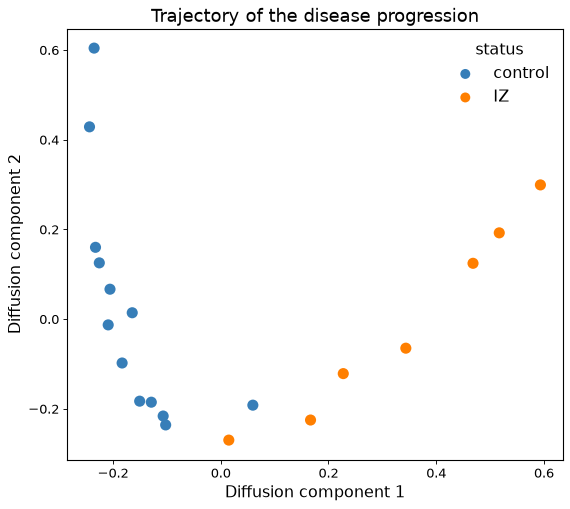

In [ ]:
pl.pl.trajectory(adata)

##### Principal graph and its nodes:
<div class="alert alert-block alert-info">
PILOT fits a principal graph (a tree) through the samples and orders them along it, starting from the root (red star). The numbers in the plot are the node numbers. We use them to choose the branches.

Note: the node numbers can change when the graph is fitted again (e.g. in a new Python session or with other settings), so always look at your own plot before choosing the nodes.
</div>

Root of the trajectory: node 6 (end node where the control samples come first).

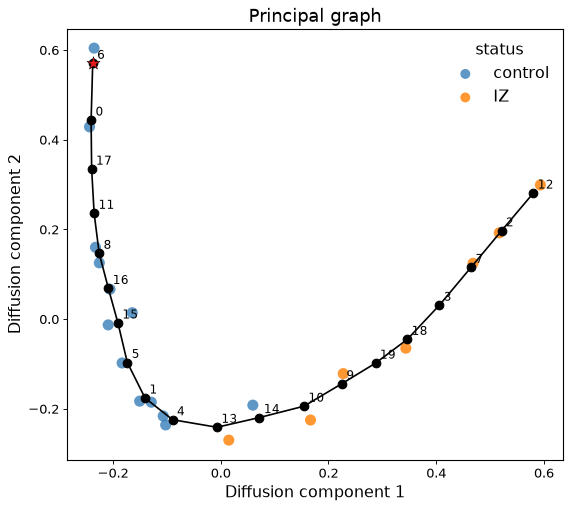

In [ ]:
pl.pl.fit_pricipla_graph(adata, source_node = 'auto', root_status = 'control')

##### Which samples belong to which node:
<div class="alert alert-block alert-info">
Each sample belongs to its nearest node of the graph. `pl.tl.sample_nodes` shows the node, the status and the pseudotime of every sample, which helps to choose the nodes of a branch.
</div>

In [ ]:
pl.tl.sample_nodes(adata)

,sampleID,node,status,pseudotime
0,RZ_P9,0,control,0.141687
1,control_P8,1,control,0.759073
2,RZ_BZ_P12,1,control,0.773940
3,IZ_P16,2,IZ,1.617639
4,RZ_FZ_P5,4,control,0.811143
5,control_P1,4,control,0.828181
6,RZ_P6,5,control,0.672575
7,control_P7,6,control,0.000000
8,GT_IZ_P13,7,IZ,1.534083
9,RZ_P11,8,control,0.410313


##### Branch 1, the healthy part:
<div class="alert alert-block alert-info">
`pl.tl.select_branch` keeps only the samples of the given nodes. All other samples are ignored in the next steps, so you can also use it to leave out samples you do not want to analyse. Parameters:

- `nodes`: the node numbers of the branch (any order), here [6, 0, 17, 11, 8, 16, 15, 5, 1, 4]: from the root to the end of the control samples.
- `name`: the name of the branch, used in the plot titles and in the names of the result folders.

The Wasserstein distances, the trajectory and the graph are not changed. `pl.pl.principal_graph` now shows the branch in orange; the other samples are faded.
</div>

Branch 'healthy part': 12 of 20 samples (control: 12, IZ: 0).

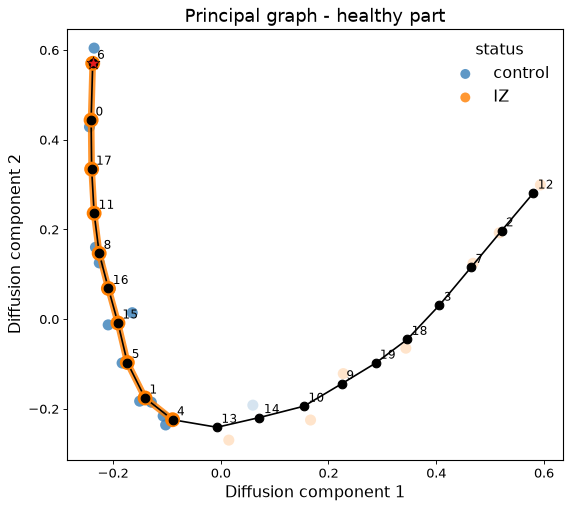

In [ ]:
pl.tl.select_branch(adata, nodes = [6, 0, 17, 11, 8, 16, 15, 5, 1, 4], name = 'healthy part')
pl.pl.principal_graph(adata)

##### Cell type importance of the healthy part:
<div class="alert alert-block alert-info">
The next steps work as usual, but only use the samples of the branch, ordered along the trajectory. The results are saved in sub-folders named after the branch (e.g. 'Results_PILOT/plots/Cell_type_Report/branch_healthy_part').
</div>

In [ ]:
pl.tl.cell_importance_calculation(adata)

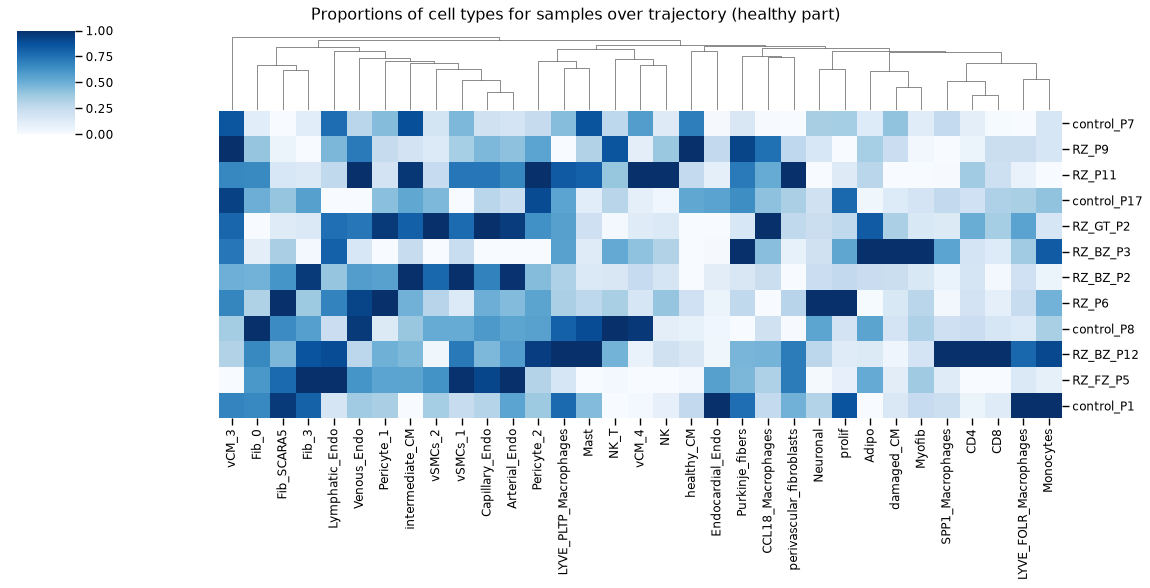

In [ ]:
pl.pl.heatmap_proportions(adata)

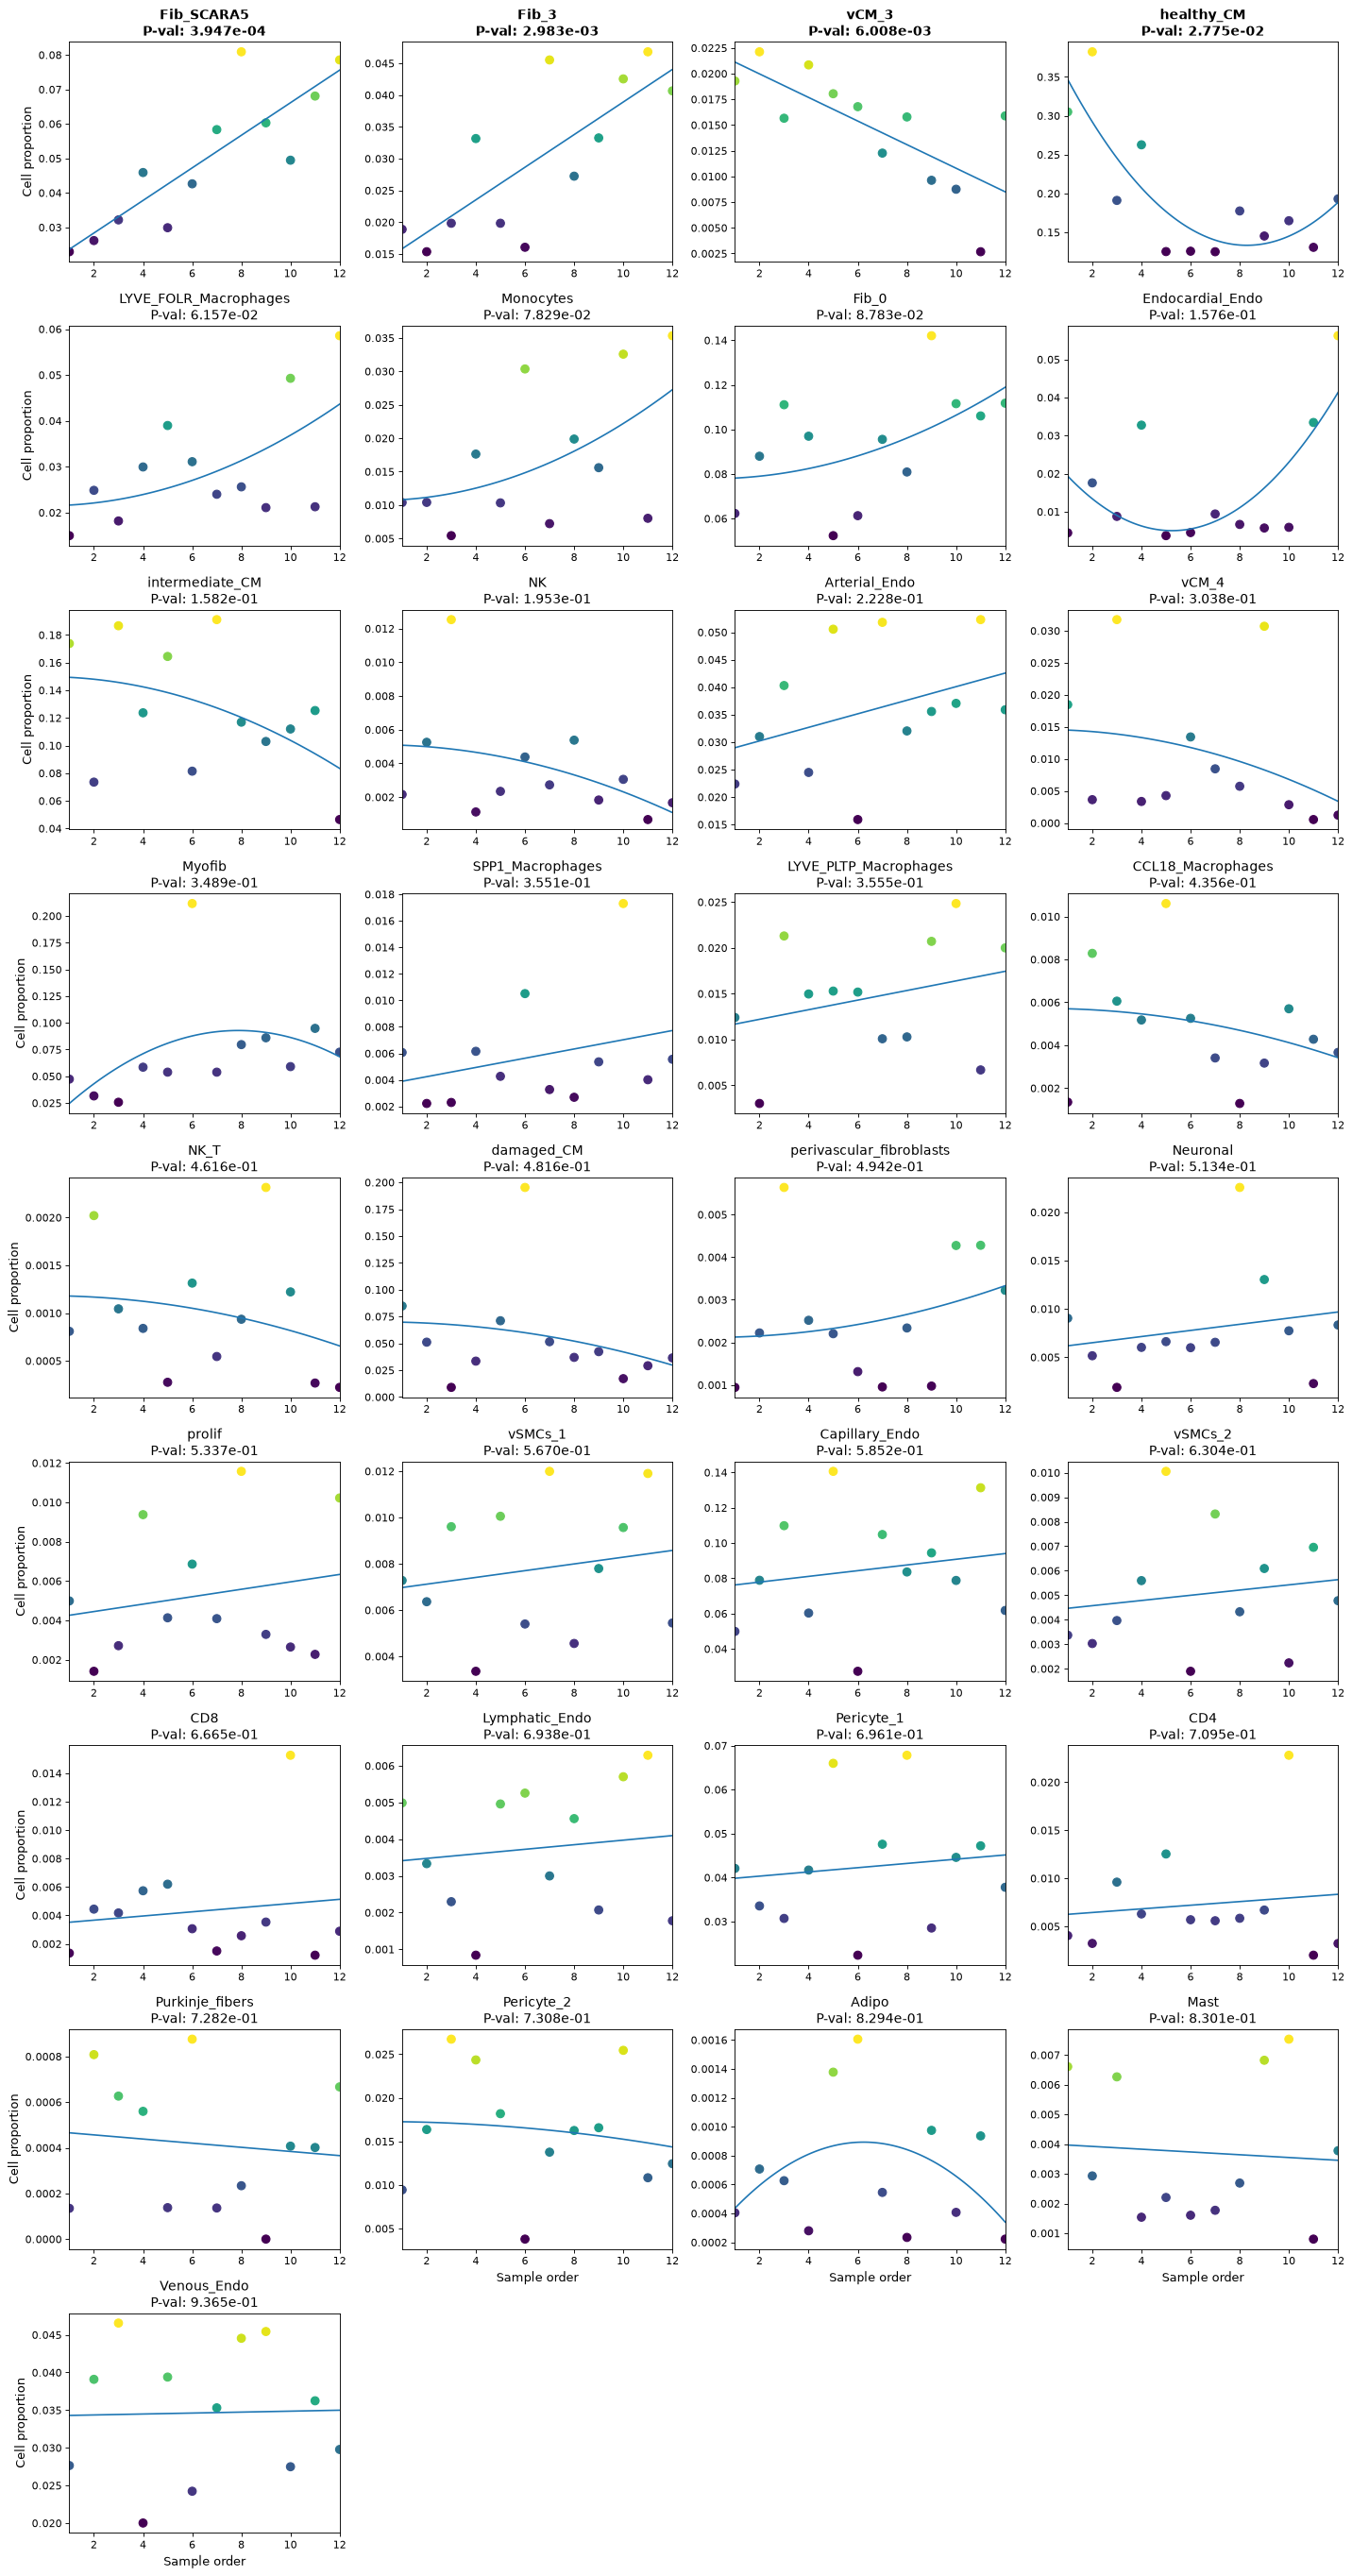

In [ ]:
pl.pl.cell_importance_grid(adata)

##### Branch 2, the disease part:
<div class="alert alert-block alert-info">
Now we choose the second branch, here the nodes [1, 4, 13, 14, 10, 9, 19, 18, 3, 7, 2, 12]: from the end of the healthy part to the end of the trajectory. We repeat the analysis. Nodes can be part of both branches (here the last two nodes of the healthy part).
</div>

Branch 'disease part': 12 of 20 samples (IZ: 7, control: 5).

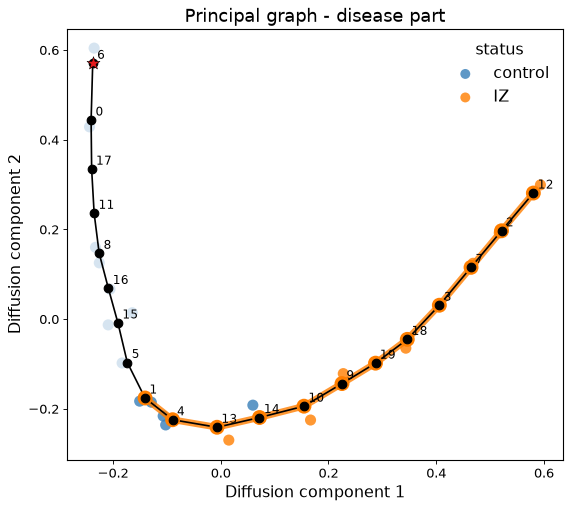

In [ ]:
pl.tl.select_branch(adata, nodes = [1, 4, 13, 14, 10, 9, 19, 18, 3, 7, 2, 12], name = 'disease part')
pl.pl.principal_graph(adata)

In [ ]:
pl.tl.cell_importance_calculation(adata)

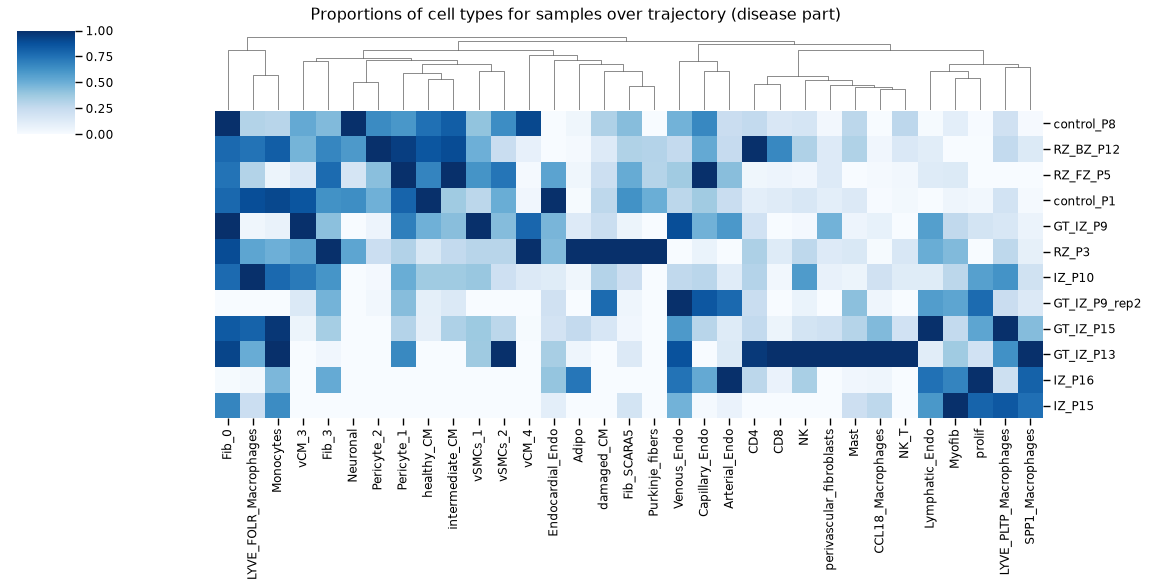

In [ ]:
pl.pl.heatmap_proportions(adata)

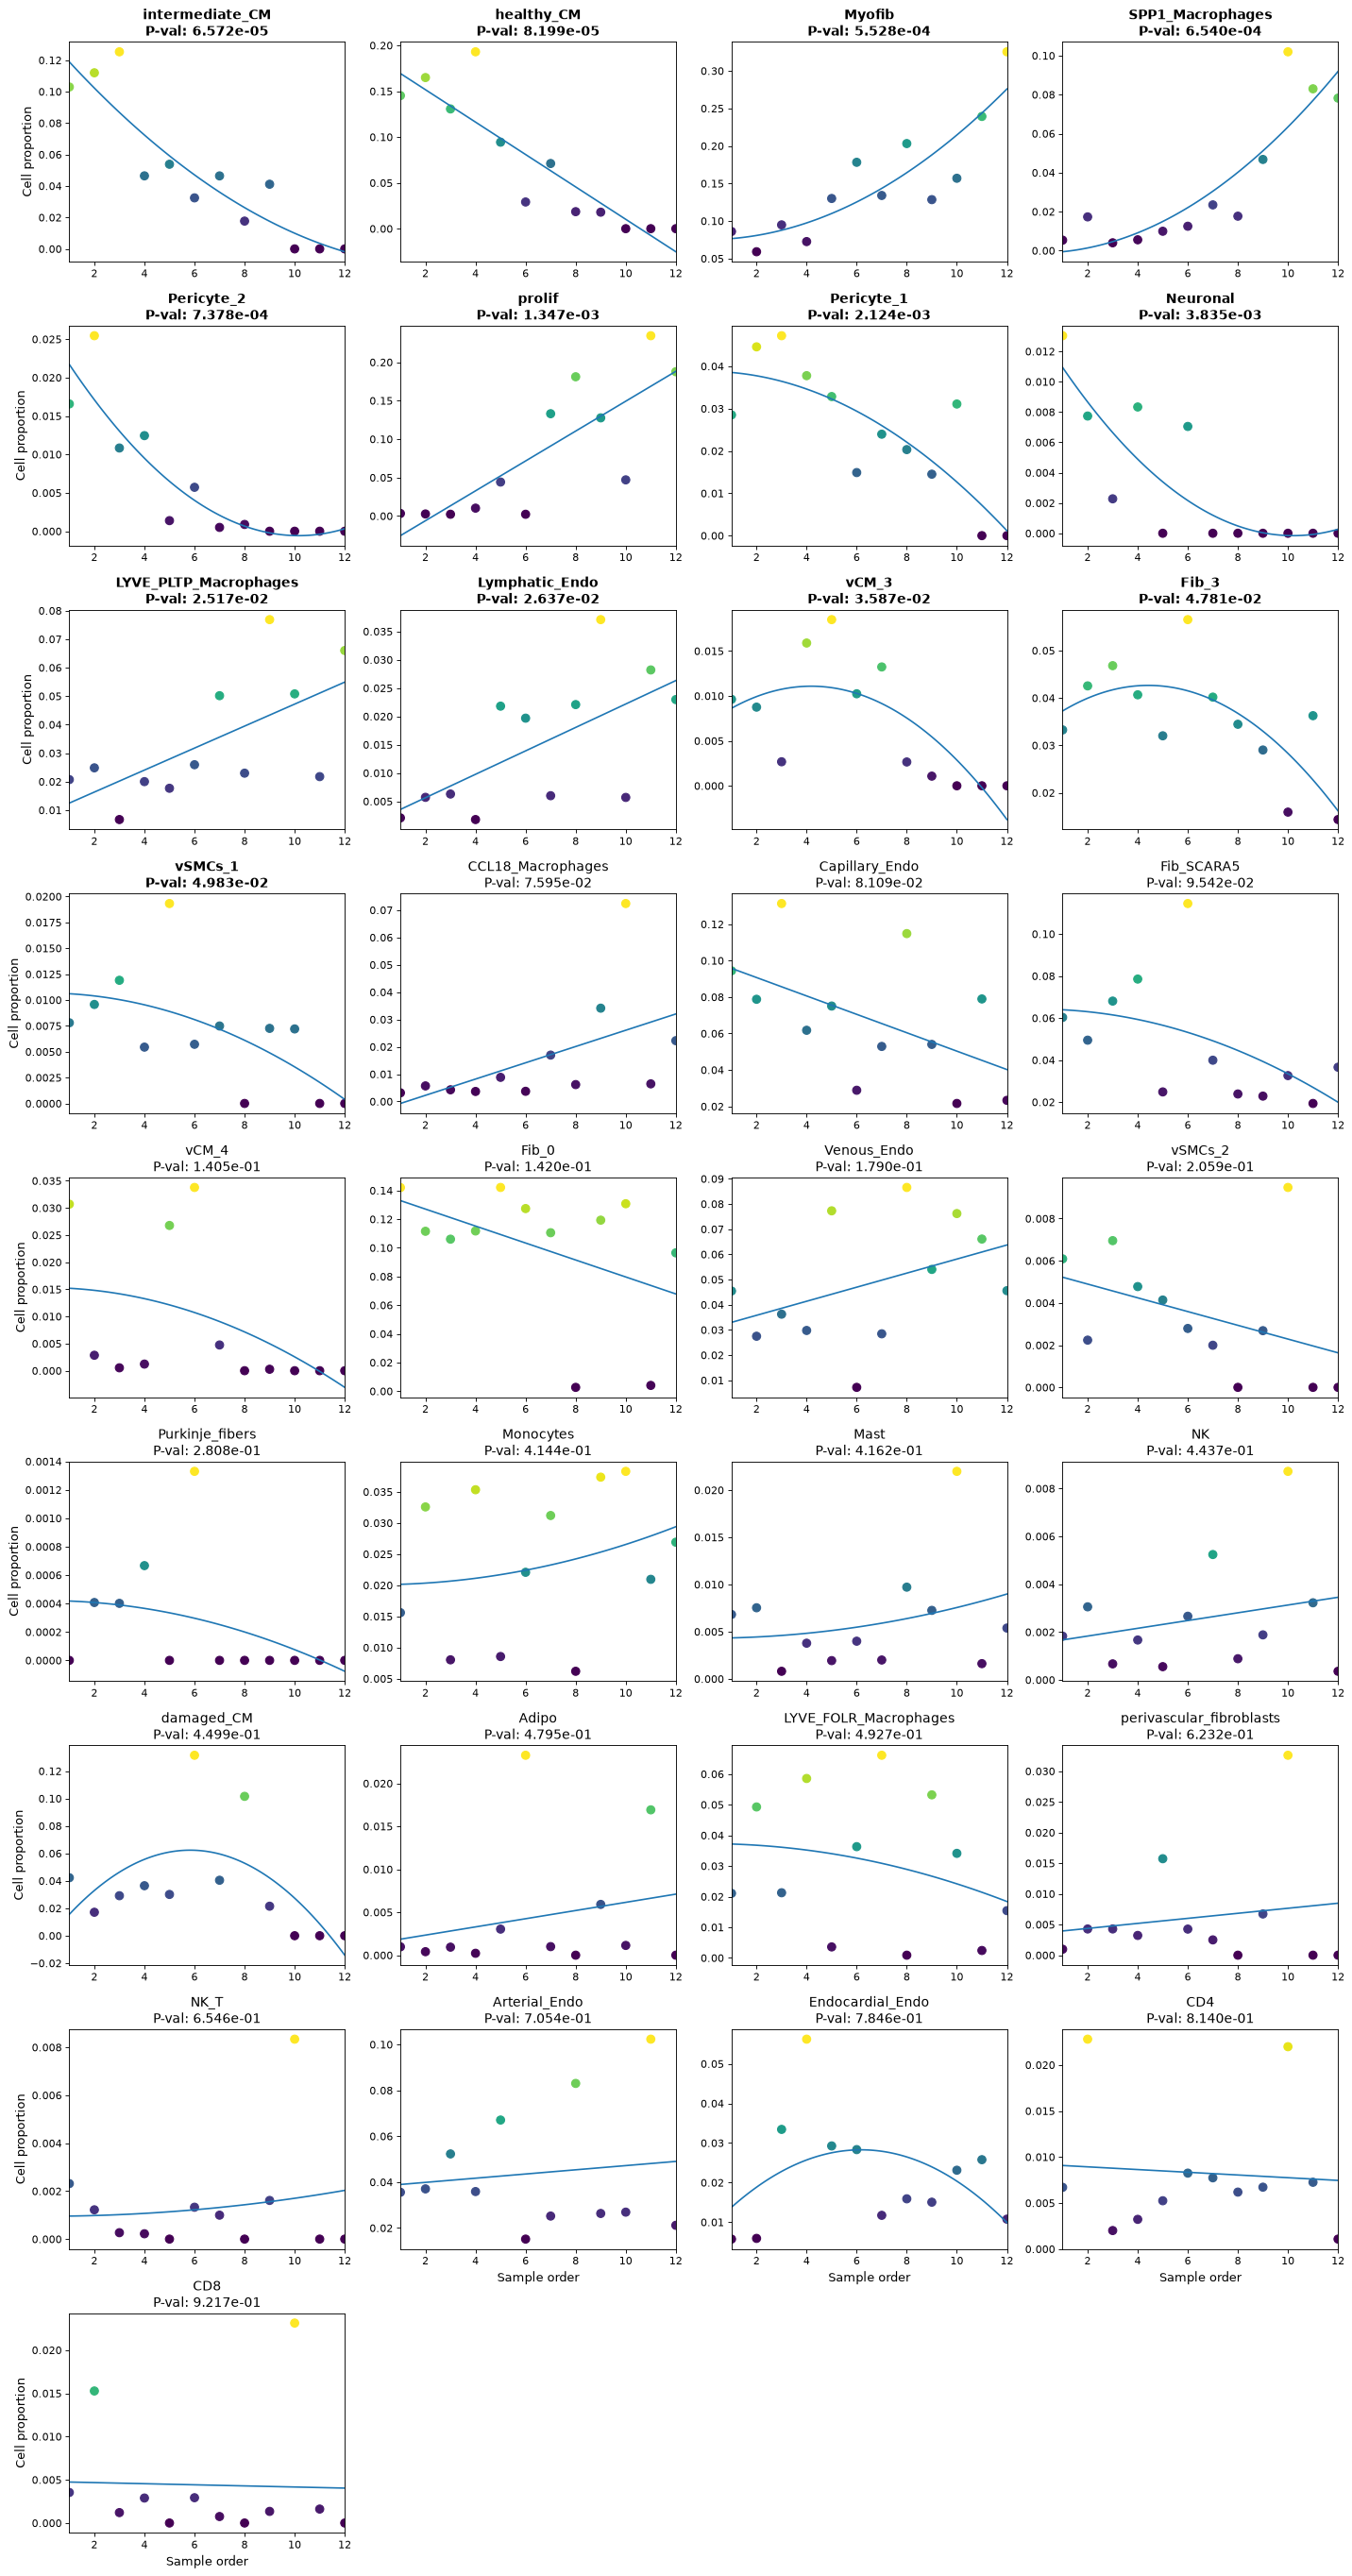

In [ ]:
pl.pl.cell_importance_grid(adata)

##### Both branches side by side:
<div class="alert alert-block alert-info">
With `ax`, the principal graphs of the branches can be drawn next to each other.
</div>

Branch 'healthy part': 12 of 20 samples (control: 12, IZ: 0).
Branch 'disease part': 12 of 20 samples (IZ: 7, control: 5).

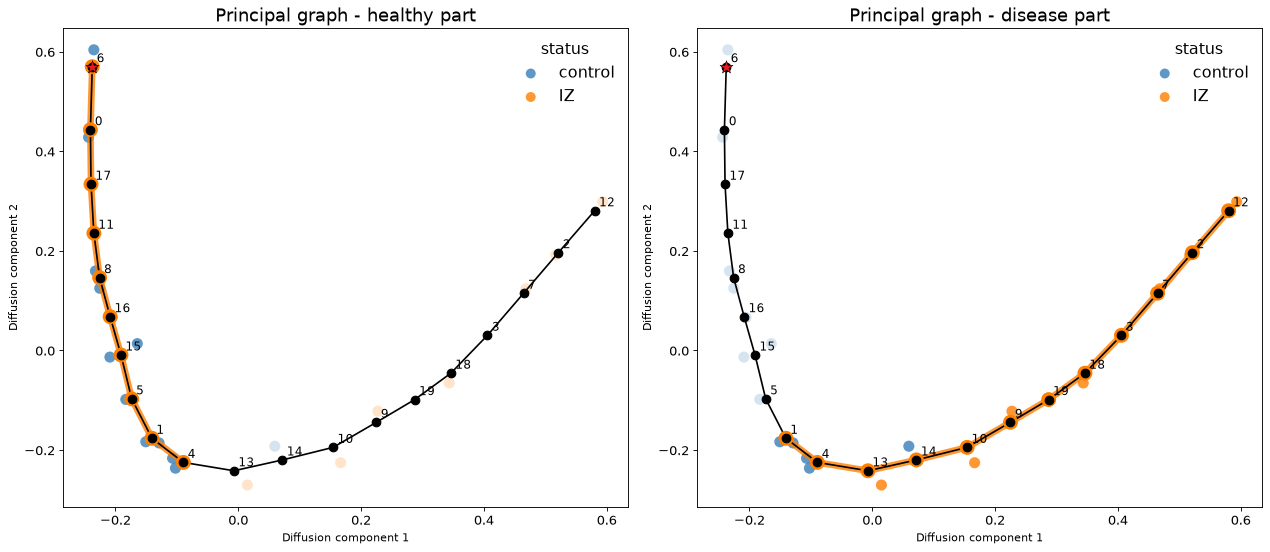

In [ ]:
fig, axes = plt.subplots(1, 2, figsize = (16, 7))
pl.tl.select_branch(adata, nodes = [6, 0, 17, 11, 8, 16, 15, 5, 1, 4], name = 'healthy part')
pl.pl.principal_graph(adata, ax = axes[0])
pl.tl.select_branch(adata, nodes = [1, 4, 13, 14, 10, 9, 19, 18, 3, 7, 2, 12], name = 'disease part')
pl.pl.principal_graph(adata, ax = axes[1])
plt.tight_layout()
plt.show()

##### Back to all samples:
<div class="alert alert-block alert-info">
`nodes = None` removes the selection, so all samples are used again (for example before the gene analysis of the Myocardial Infarction tutorial).
</div>

In [ ]:
pl.tl.select_branch(adata, nodes = None)
pl.tl.cell_importance_calculation(adata)

No branch selected: all samples are used.

##### Summary:
<div class="alert alert-block alert-info">
Splitting the trajectory shows which cell types change in which part of the disease progression. In this data, only a few cell types change in the healthy part, while in the disease part the healthy cardiomyocytes (`healthy_CM`) decrease and myofibroblasts (`Myofib`), `SPP1_Macrophages` and proliferating cells (`prolif`) increase.

The same works for any trajectory: look at the principal graph, choose the nodes of each branch (or leave out the nodes of samples you do not want to analyse), and run the analysis for each branch.
</div>